In [265]:
import pandas as pd
import numpy as np
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, log_loss, 
                             classification_report, average_precision_score, precision_recall_curve)
from catboost import CatBoostClassifier

import optuna

import warnings
warnings.filterwarnings("ignore")

In [266]:
pd.set_option('display.max_columns', None)

# Preprocessing Data

In [267]:
# Import the data since we want to be able to change our experiments individually.
Xt = pd.read_csv("modeling_data/train.csv")
yt = Xt["target"]
# Xt.drop(columns=["target"],inplace=True)
Xv = pd.read_csv("modeling_data/validation.csv")
yv = Xv["target"]
Xv.drop(columns=["target"],inplace=True)

Xt.drop(columns=["patient_nbr"],inplace=True)
Xv.drop(columns=["patient_nbr"],inplace=True)

In [268]:
# Xt.columns.to_list()

In [269]:
def group_medications(df):
    groups = {
        "biguanide": ["metformin"],
        "meglitinide": ["repaglinide", "nateglinide"],
        "sulfonylurea_gen1": ["chlorpropamide", "acetohexamide", "tolbutamide", "tolazamide"],
        "sulfonylurea_gen2": ["glimepiride", "glipizide", "glyburide"],
        "thiazolidinedione": ["pioglitazone", "rosiglitazone", "troglitazone"],
        "alpha_glucosidase_inhibitor": ["acarbose", "miglitol"],
        "biguanide_sulfonylurea_gen2": ["glyburide-metformin", "glipizide-metformin"],
        "biguanide_thiazolidinedione": ["metformin-rosiglitazone", "metformin-pioglitazone"],
        "sulfonylurea_gen2_thiazolidinedione": ["glimepiride-pioglitazone"],
    }

    result = df.copy()
    priority = ["Up", "Down", "Steady"]

    for group, medications in groups.items():
        columns = df.columns.intersection(medications)
        if len(columns):
            values = df[columns]
            result = result.drop(columns=columns)
            result[group] = np.select([values.eq(status).any(axis=1) for status in priority], priority, default="No")

    return result

Xt=group_medications(Xt)
Xv=group_medications(Xv)

In [270]:
# Removing outliers

# Remove entries 4 standard deviations out
def remove_upper_outliers(df, columns, n_std=5):
    x = df[columns]
    upper = x.mean() + n_std * x.std(ddof=0)
    remove = x.gt(upper).any(axis=1)

    print(f"Removed {remove.sum():,} of {len(df):,} rows")
    return df.loc[~remove].copy()

numerical_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
]

train_filtered = remove_upper_outliers(Xt, numerical_features)

Xt = train_filtered.drop(columns="target")
yt = train_filtered["target"]

Removed 1,021 of 65,129 rows


In [271]:
def add_numerical_entries(df):

    df['total_visits'] = df['number_outpatient'] + df['number_inpatient'] + df['number_outpatient']

    return df

In [272]:
def group_diagnoses(df):
    import pandas as pd

    ranges = {
        "Circulatory": (390, 459),
        "Respiratory": (460, 519),
        "Digestive": (520, 579),
        "Genitourinary": (580, 629),
        "Musculoskeletal": (710, 739),
        "Neoplasms": (140, 239),
        "Injury": (800, 999),
    }
    symptoms = {
        785: "Circulatory",
        786: "Respiratory",
        787: "Digestive",
        788: "Genitourinary",
    }

    def categorize(value):
        if pd.isna(value):
            return "Missing"

        code = str(value).strip().upper()
        if code in {"", "?", "NAN", "NONE", "MISSING"}:
            return "Missing"

        # Supplementary V/E codes belong to the broad Other category.
        if code.startswith(("V", "E")):
            return "Other"

        try:
            number = float(code)
            if not 1 <= number < 1000:
                return "Other"
            code = int(number)  # 250.13 -> 250, 459.9 -> 459
        except ValueError:
            return "Other"

        if code == 250:
            return "Diabetes"
        if code in symptoms:
            return symptoms[code]
        for group, (lower, upper) in ranges.items():
            if lower <= code <= upper:
                return group
        return "Other"

    result = df.copy()
    for column in ("diag_1", "diag_2", "diag_3", "diaga_3"):
        if column in result.columns:
            result[column] = result[column].map(categorize)

    return result


Xt = group_diagnoses(Xt)
Xv = group_diagnoses(Xv)

In [273]:
# prepare for catboost
num_cols = Xt.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in Xt.columns if c not in num_cols]


# careful! catboost demands categorical columns to have string entry
Xt_cb, Xv_cb = Xt.copy(), Xv.copy()
for c in cat_cols:
    for df in (Xt_cb, Xv_cb):
        df[c] = df[c].astype(object).where(df[c].notna(), "missing").astype(str)

In [274]:
Xt.head(10)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,a1cresult,examide,citoglipton,insulin,change,diabetesmed,biguanide,meglitinide,sulfonylurea_gen1,sulfonylurea_gen2,thiazolidinedione,alpha_glucosidase_inhibitor,biguanide_sulfonylurea_gen2,biguanide_thiazolidinedione,sulfonylurea_gen2_thiazolidinedione
0,1,41,0,1,0,0,0,1,Caucasian,Female,[0-10),?,NaN,Not Mapped,Physician Referral,Pediatrics-Endocrinology,Diabetes,Missing,Missing,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No
1,3,59,0,18,0,0,0,9,Caucasian,Female,[10-20),?,Emergency,Discharged to home,Emergency Room,?,Other,Diabetes,Other,NaN,NaN,No,No,Up,Ch,Yes,No,No,No,No,No,No,No,No,No
2,2,44,1,16,0,0,0,7,Caucasian,Male,[30-40),?,Emergency,Discharged to home,Emergency Room,?,Other,Diabetes,Circulatory,NaN,NaN,No,No,Up,Ch,Yes,No,No,No,No,No,No,No,No,No
3,3,31,6,16,0,0,0,9,Caucasian,Male,[50-60),?,Urgent,Discharged to home,Clinic Referral,?,Circulatory,Circulatory,Diabetes,NaN,NaN,No,No,Steady,No,Yes,No,No,No,No,No,No,No,No,No
4,4,70,1,21,0,0,0,7,Caucasian,Male,[60-70),?,Elective,Discharged to home,Clinic Referral,?,Circulatory,Circulatory,Other,NaN,NaN,No,No,Steady,Ch,Yes,Steady,No,No,Steady,No,No,No,No,No
5,5,73,0,12,0,0,0,8,Caucasian,Male,[70-80),?,Emergency,Discharged to home,Emergency Room,?,Circulatory,Respiratory,Diabetes,NaN,NaN,No,No,No,No,Yes,No,No,No,Steady,No,No,No,No,No
6,9,47,2,17,0,0,0,9,AfricanAmerican,Female,[40-50),?,Emergency,Discharged to home,Emergency Room,?,Diabetes,Circulatory,Injury,NaN,NaN,No,No,Steady,No,Yes,No,No,No,No,No,No,No,No,No
7,1,49,5,2,0,0,0,8,AfricanAmerican,Female,[60-70),?,Elective,Discharged to home,Clinic Referral,?,Respiratory,Injury,Genitourinary,NaN,NaN,No,No,Steady,No,Yes,No,No,No,No,No,No,No,No,No
8,4,45,4,17,0,0,0,8,AfricanAmerican,Male,[50-60),?,Emergency,Discharged to home,Emergency Room,?,Circulatory,Circulatory,Circulatory,NaN,NaN,No,No,Steady,Ch,Yes,No,No,No,Steady,No,No,No,No,No
9,3,29,0,11,0,0,0,3,Caucasian,Female,[50-60),?,Emergency,Discharged to home,Emergency Room,Cardiology,Other,Neoplasms,Diabetes,NaN,NaN,No,No,No,No,Yes,No,No,No,Steady,No,No,No,No,No


In [275]:
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42),)

# Include a configuration as the first trial.
study.enqueue_trial({'iterations': 1000, 'learning_rate': 0.015, 'depth': 6, 'l2_leaf_reg': 3.5, 'scale_pos_weight': 4.5})

best_f1 = -1.0

for _ in range(10):
    trial = study.ask()

    # candidate = CatBoostClassifier(
    #     iterations=trial.suggest_int("iterations", 100, 3_000, step=10),
    #     learning_rate=trial.suggest_float("learning_rate", 0.001, 1.000, log=True),
    #     depth=trial.suggest_int("depth", 1, 12),
    #     l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 0.01, 100.0, log=True),
    #     scale_pos_weight=trial.suggest_float("scale_pos_weight", 0.01, 50.00, log=True),
    #     loss_function="Logloss",
    #     task_type="GPU",
    #     devices="0",
    #     random_seed=42,
    #     verbose=False,
    #     allow_writing_files=False,
    # )


    # Version where we work with further boostrap
    bootstrap = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli", "Poisson", "No"])
    bagging = {"bootstrap_type": bootstrap}

    if bootstrap == "Bayesian":
        bagging["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0.1, 1.0)
    elif bootstrap in ["Bernoulli", "Poisson"]:
        bagging["subsample"] = trial.suggest_float("subsample", 0.1, 1.0)

    candidate = CatBoostClassifier(
        iterations=trial.suggest_int("iterations", 100, 1_500, step=100),
        learning_rate=trial.suggest_float("learning_rate", 0.001, 1.000, log=True),
        depth=trial.suggest_int("depth", 1, 12),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 0.01, 100.0, log=True),
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 0.01, 50.00, log=True),
        **bagging,
        loss_function="Logloss",
        task_type="GPU",
        devices="0",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )

    candidate.fit(Xt_cb, yt, cat_features=cat_cols)
    trial_proba = candidate.predict_proba(Xv_cb)[:, 1]

    # chooses a new optimal threshold
    p, r, thr = precision_recall_curve(yv, trial_proba)
    f1s = (
        2 * p[:-1] * r[:-1]
        / np.maximum(p[:-1] + r[:-1], 1e-15)
    )

    best_index = int(np.argmax(f1s))
    trial_f1 = float(f1s[best_index])
    trial_threshold = float(thr[best_index])

    trial.set_user_attr("threshold", trial_threshold)
    study.tell(trial, trial_f1)

    # keep the winning model for later use
    if trial_f1 > best_f1:
        best_f1 = trial_f1
        model = candidate
        proba = trial_proba
        threshold = trial_threshold

    print(f"Trial {trial.number:02d} | F1={trial_f1:.4f} | threshold={trial_threshold:.4f} | best={best_f1:.4f}")

y_pred = (proba >= threshold).astype(int)

print("\nBest parameters:", study.best_params)
print(f"Best threshold: {threshold:.4f}")
print(f"F1 @0.5: {f1_score(yv, proba >= 0.5):.4f}")
print(f"Threshold-optimized F1: {best_f1:.4f}")
print("\nConfusion matrix:\n", confusion_matrix(yv, y_pred))
print(classification_report(yv, y_pred, digits=4, zero_division=0))

[I 2026-10-25 13:58:02,650] A new study created in memory with name: no-name-6b1ee05e-7699-46d3-a5eb-8b3cc15f4e94


Trial 00 | F1=0.2891 | threshold=0.4088 | best=0.2891
Trial 01 | F1=0.2613 | threshold=0.0075 | best=0.2891
Trial 02 | F1=0.2500 | threshold=0.0706 | best=0.2891
Trial 03 | F1=0.2769 | threshold=0.8205 | best=0.2891
Trial 04 | F1=0.2787 | threshold=0.0133 | best=0.2891


KeyboardInterrupt: 

In [ ]:
best_parameters = study.best_params
print(best_parameters)
best_threshold = threshold
print(threshold)

cbc = CatBoostClassifier(**best_parameters,
        verbose=250,
        loss_function="Logloss",
        task_type="GPU",
        devices="0",
        random_seed=42,
        allow_writing_files=False)
cbc.fit(Xt_cb,yt, cat_features=cat_cols)

{'bootstrap_type': 'Bernoulli', 'subsample': 0.887078230198951, 'iterations': 790, 'learning_rate': 0.022269865931716336, 'depth': 10, 'l2_leaf_reg': 2.125988045219766, 'scale_pos_weight': 0.8652436362211865}
0.12757194420233475
0:	learn: 0.6721619	total: 81ms	remaining: 1m 3s
250:	learn: 0.2770329	total: 21.3s	remaining: 45.8s
500:	learn: 0.2588839	total: 41.6s	remaining: 24s
750:	learn: 0.2425388	total: 1m 2s	remaining: 3.24s
789:	learn: 0.2398037	total: 1m 5s	remaining: 0us


CatBoostClassifier(allow_writing_files=False, bootstrap_type='Bernoulli', depth=10, devices='0', iterations=790, l2_leaf_reg=2.125988045219766, learning_rate=0.022269865931716336, loss_function='Logloss', random_seed=42, scale_pos_weight=0.8652436362211865, subsample=0.887078230198951, task_type='GPU', verbose=250)

In [ ]:
proba = cbc.predict_proba(Xv_cb)[:, 1]

threshold = 0.5
y_pred = (proba >= threshold).astype(int)

print("ROC-AUC:", round(roc_auc_score(yv, proba), 4))
print("PR-AUC: ", round(average_precision_score(yv, proba), 4))
print(f"Accuracy: {accuracy_score(yv, y_pred):.3f}")
print("\nConfusion matrix:\n", confusion_matrix(yv, y_pred))
print(f"\n\n{classification_report(yv, y_pred)}")
print(f"\nF1 @{threshold}: {round(f1_score(yv,y_pred),4)}")

# Best-threshold F1 (optimistic: threshold chosen on Xv itself)
p, r, thr = precision_recall_curve(yv, proba)
f1s = 2 * p * r / (p + r + 1e-12)
best = f1s[:-1].argmax()
print(f"\nBest-threshold F1: {f1s[best]:.4f} at threshold {thr[best]:.4f}")

ROC-AUC: 0.684
PR-AUC:  0.2345
Accuracy: 0.889

Confusion matrix:
 [[14460     6]
 [ 1802    15]]


              precision    recall  f1-score   support

           0       0.89      1.00      0.94     14466
           1       0.71      0.01      0.02      1817

    accuracy                           0.89     16283
   macro avg       0.80      0.50      0.48     16283
weighted avg       0.87      0.89      0.84     16283


F1 @0.5: 0.0163

Best-threshold F1: 0.2968 at threshold 0.1276


# Error Analysis

In [ ]:
cbc = model
best_threshold = study.best_trial.user_attrs["threshold"]

proba = cbc.predict_proba(Xv_cb)[:, 1]
y_pred = (proba >= best_threshold).astype(int)

Xv["target"] = yv
Xv["y_pred"] = y_pred

In [ ]:
Errors = Xv[Xv["target"] != Xv["y_pred"]]

In [ ]:
Errors

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race,gender,...,meglitinide,sulfonylurea_gen1,sulfonylurea_gen2,thiazolidinedione,alpha_glucosidase_inhibitor,biguanide_sulfonylurea_gen2,biguanide_thiazolidinedione,sulfonylurea_gen2_thiazolidinedione,target,y_pred
3,7,62,0,11,0,0,0,7,AfricanAmerican,Male,...,No,No,Up,No,No,No,No,No,1,0
6,1,53,0,10,0,0,0,8,AfricanAmerican,Male,...,No,No,No,No,No,No,No,No,0,1
13,5,34,0,17,0,0,1,7,Caucasian,Female,...,No,No,No,No,No,No,No,No,0,1
26,7,55,1,16,0,0,1,7,Caucasian,Female,...,No,No,No,No,No,No,No,No,0,1
29,2,18,0,15,5,1,0,3,Caucasian,Female,...,No,No,No,No,No,No,No,No,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16259,8,42,0,24,0,0,1,9,Caucasian,Female,...,No,No,Steady,No,No,No,No,No,0,1
16262,1,17,3,6,0,0,3,6,Caucasian,Female,...,No,No,No,No,No,No,No,No,0,1
16271,5,66,0,24,0,0,3,9,Caucasian,Female,...,No,No,No,No,No,No,No,No,0,1
16273,4,64,4,23,0,0,0,9,Caucasian,Male,...,No,No,No,No,No,No,No,No,1,0


In [ ]:
Errors

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race,gender,...,meglitinide,sulfonylurea_gen1,sulfonylurea_gen2,thiazolidinedione,alpha_glucosidase_inhibitor,biguanide_sulfonylurea_gen2,biguanide_thiazolidinedione,sulfonylurea_gen2_thiazolidinedione,target,y_pred
3,7,62,0,11,0,0,0,7,AfricanAmerican,Male,...,No,No,Up,No,No,No,No,No,1,0
6,1,53,0,10,0,0,0,8,AfricanAmerican,Male,...,No,No,No,No,No,No,No,No,0,1
13,5,34,0,17,0,0,1,7,Caucasian,Female,...,No,No,No,No,No,No,No,No,0,1
26,7,55,1,16,0,0,1,7,Caucasian,Female,...,No,No,No,No,No,No,No,No,0,1
29,2,18,0,15,5,1,0,3,Caucasian,Female,...,No,No,No,No,No,No,No,No,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16259,8,42,0,24,0,0,1,9,Caucasian,Female,...,No,No,Steady,No,No,No,No,No,0,1
16262,1,17,3,6,0,0,3,6,Caucasian,Female,...,No,No,No,No,No,No,No,No,0,1
16271,5,66,0,24,0,0,3,9,Caucasian,Female,...,No,No,No,No,No,No,No,No,0,1
16273,4,64,4,23,0,0,0,9,Caucasian,Male,...,No,No,No,No,No,No,No,No,1,0


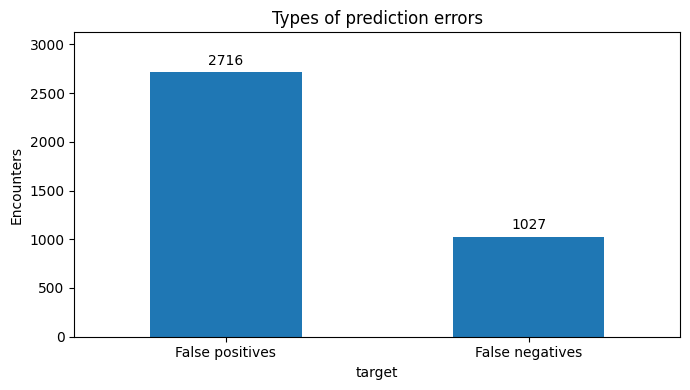

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

audit = Xv.copy()

audit["result"] = "TN"
audit.loc[audit["target"].eq(0) & audit["y_pred"].eq(1), "result"] = "FP"
audit.loc[audit["target"].eq(1) & audit["y_pred"].eq(0), "result"] = "FN"
audit.loc[audit["target"].eq(1) & audit["y_pred"].eq(1), "result"] = "TP"

error_counts = (Errors["target"].map({0: "False positives", 1: "False negatives"}).value_counts().reindex(["False positives", "False negatives"], fill_value=0))

ax = error_counts.plot.bar(figsize=(7, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_ylabel("Encounters")
ax.set_title("Types of prediction errors")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

number_inpatient        number_emergency        time_in_hospital  \
                   mean median             mean median             mean   
result                                                                    
FP                 1.85    2.0              0.4    0.0             5.21   
TP                 2.23    2.0              0.6    0.0             5.16   

              num_medications         
       median            mean median  
result                                
FP        5.0           17.75   17.0  
TP        4.0           18.55   17.0

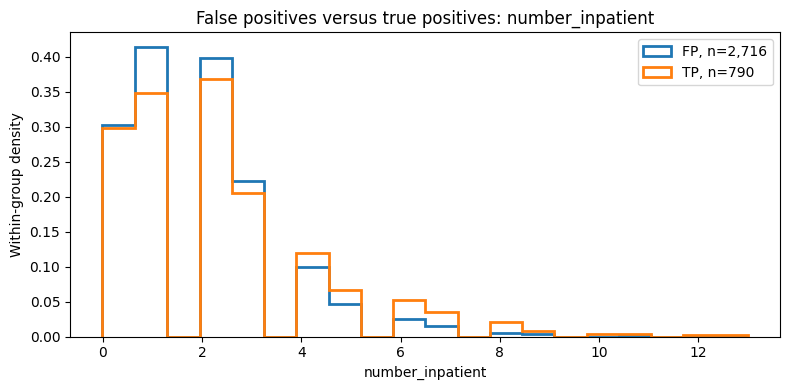

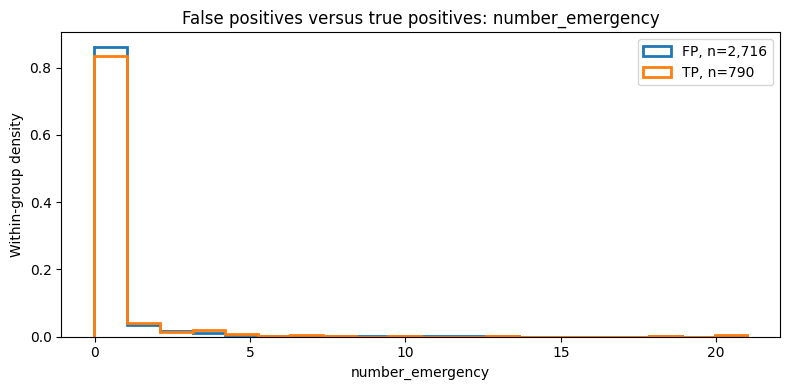

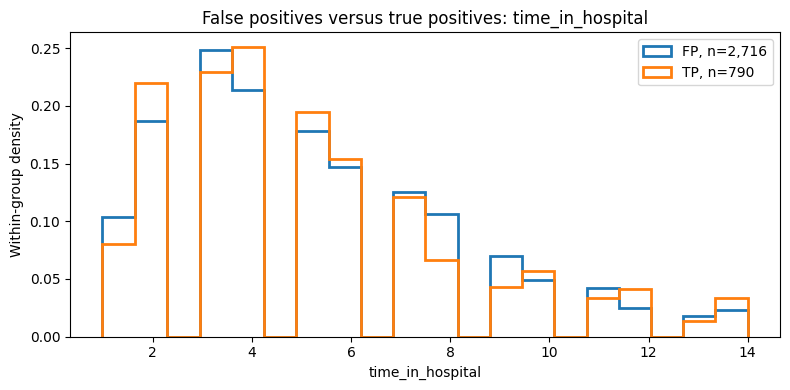

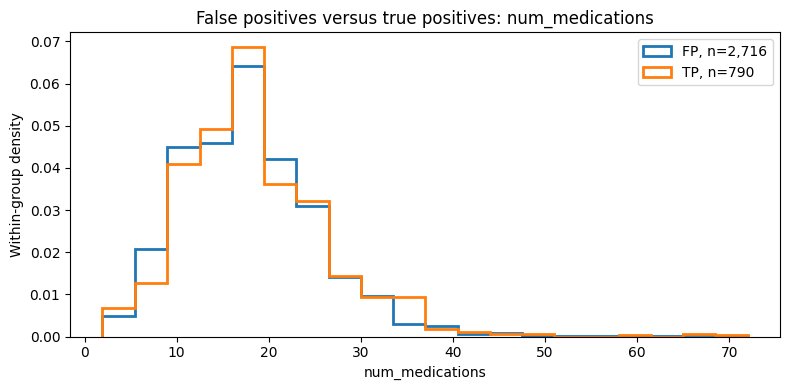

In [ ]:
flagged = audit.loc[audit["y_pred"].eq(1)].copy()

columns = ["number_inpatient", "number_emergency", "time_in_hospital", "num_medications",]

display(flagged.groupby("result")[columns].agg(["mean", "median"]).round(2))

for column in columns:
    values = pd.to_numeric(flagged[column], errors="coerce")

    # use identical bin edges for both groups.
    edges = pd.cut(values.dropna(), bins=20, retbins=True)[1]

    plt.figure(figsize=(8, 4))

    for result in ["FP", "TP"]:
        group = values.loc[flagged["result"].eq(result)].dropna()
        plt.hist(group, bins=edges, density=True, histtype="step", linewidth=2, label=f"{result}, n={len(group):,}")

    plt.xlabel(column)
    plt.ylabel("Within-group density")
    plt.title(f"False positives versus true positives: {column}")
    plt.legend()
    plt.tight_layout()
    plt.show()

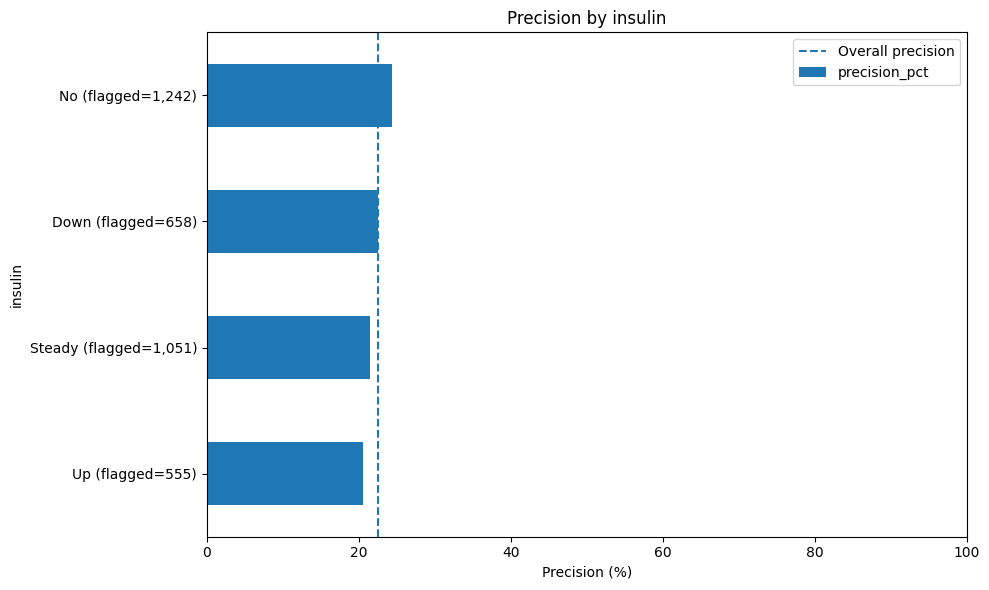

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
insulin,,,,,,,,
No,5780,940,476,302,1242,24.32,13.99,61.18
Steady,3591,825,300,226,1051,21.50,18.68,57.03
Down,1235,510,135,148,658,22.49,29.23,47.70
Up,1144,441,116,114,555,20.54,27.82,50.43


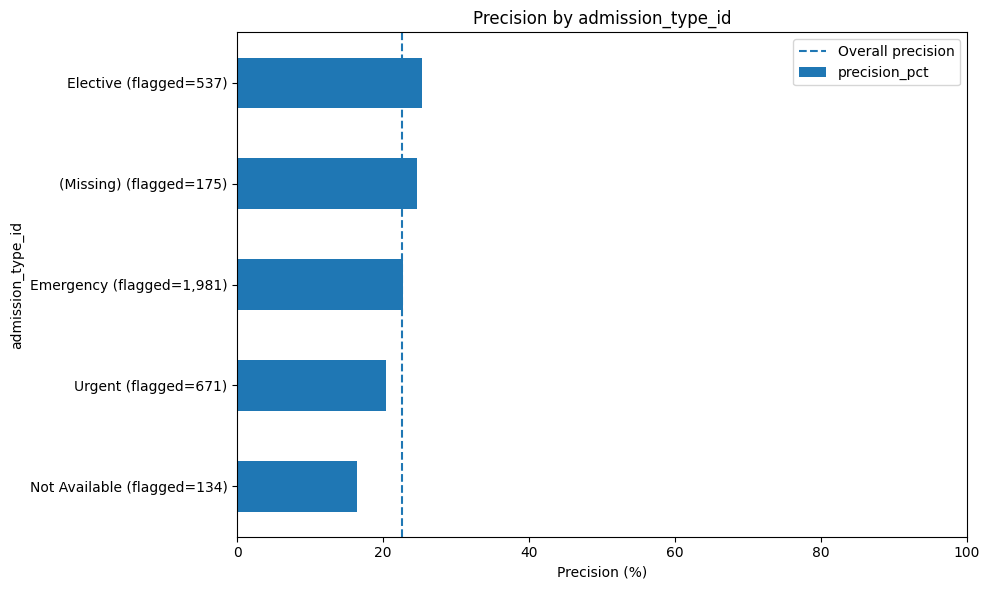

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
admission_type_id,,,,,,,,
Emergency,6097,1531,562,450,1981,22.72,20.07,55.53
Urgent,2067,534,180,137,671,20.42,20.53,56.78
Elective,2370,401,176,136,537,25.33,14.47,56.41
(Missing),605,132,48,43,175,24.57,17.91,52.75
Not Available,551,112,58,22,134,16.42,16.89,72.50
Not Mapped,53,5,3,2,7,28.57,8.62,60.00
Trauma Center,4,1,0,0,1,0.00,20.00,NaN
Newborn,3,0,0,0,0,NaN,0.00,NaN


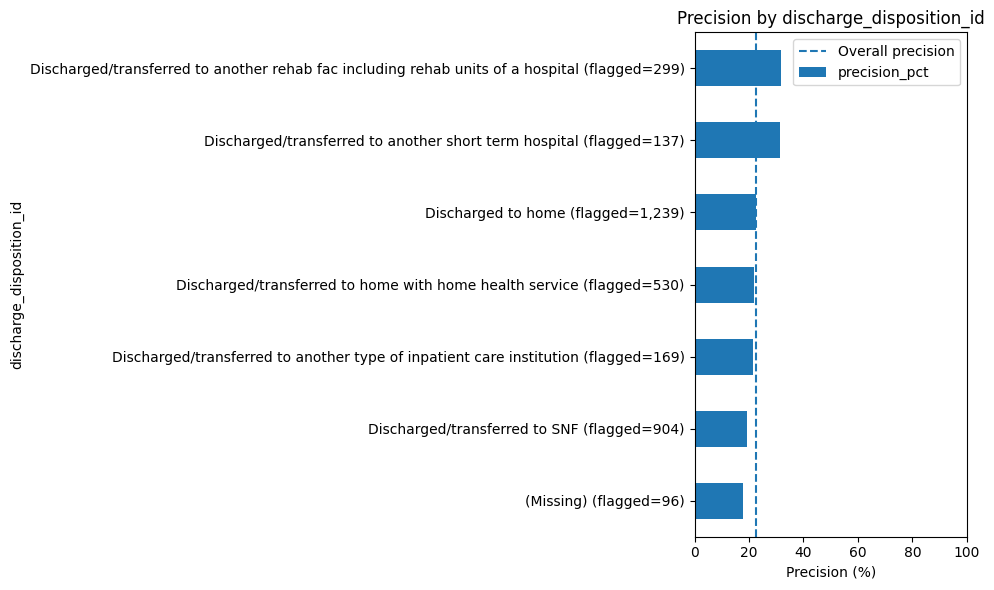

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
discharge_disposition_id,,,,,,,,
Discharged to home,7762,959,623,280,1239,22.60,11.00,68.99
Discharged/transferred to SNF,1164,731,149,173,904,19.14,38.58,46.27
Discharged/transferred to home with home health service,1318,415,132,115,530,21.70,23.95,53.44
Discharged/transferred to another rehab fac including rehab units of a hospital,28,204,6,95,299,31.77,87.93,5.94
Discharged/transferred to another type of inpatient care institution,52,133,8,36,169,21.30,71.89,18.18
Discharged/transferred to another short term hospital,213,94,11,43,137,31.39,30.62,20.37
(Missing),444,79,54,17,96,17.71,15.11,76.06
Discharged/transferred to ICF,91,28,8,10,38,26.32,23.53,44.44
Discharged/transferred/referred to a psychiatric hospital of psychiatric distinct part unit of a hospital,2,15,1,8,23,34.78,88.24,11.11


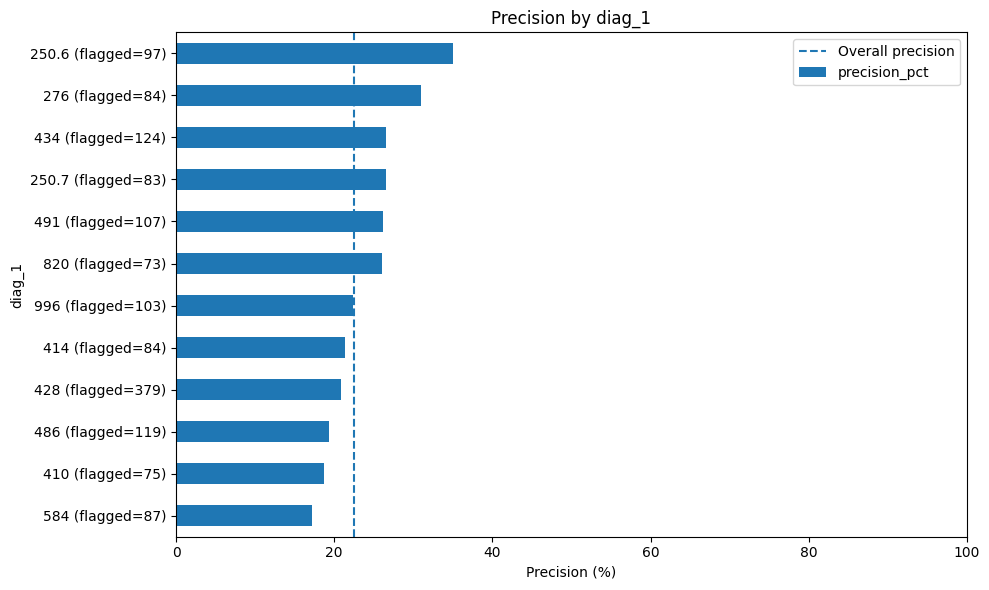

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
diag_1,,,,,,,,
428,634,300,77,79,379,20.84,32.12,49.36
486,431,96,22,23,119,19.33,18.22,48.89
434,180,91,25,33,124,26.61,33.58,43.10
996,178,80,20,23,103,22.33,31.01,46.51
491,246,79,31,28,107,26.17,24.31,52.54
584,161,72,13,15,87,17.24,30.90,46.43
414,895,66,78,18,84,21.43,6.87,81.25
250.6,92,63,14,34,97,35.05,40.65,29.17
410,458,61,43,14,75,18.67,11.75,75.44


In [ ]:
# We perform error analysis on based on grouping of insulin, admission types, discharge dispositions, and the actual diagnoses

group_tables = {}
overall_precision = 100 * flagged["target"].mean()

for column in ["insulin", "admission_type_id", "discharge_disposition_id","diag_1"]:
    groups = audit[column].astype("string").fillna("(Missing)")

    table = pd.crosstab(groups, audit["result"]).reindex(columns=["TN", "FP", "FN", "TP"], fill_value=0)

    table["flagged"] = table["TP"] + table["FP"]
    negatives = table["TN"] + table["FP"]
    positives = table["TP"] + table["FN"]

    table["precision_pct"] = 100 * table["TP"] / table["flagged"].where(table["flagged"] > 0)
    

    table["FPR_pct"] = 100 * table["FP"] / negatives.where(negatives > 0)

    table["FNR_pct"] = 100 * table["FN"] / positives.where(positives > 0)

    group_tables[column] = table

    # Show common groups with at least 50 positive predictions.
    shown = table.loc[table["flagged"] >= 50].nlargest(12, "flagged").sort_values("precision_pct")

    ax = shown["precision_pct"].plot.barh(figsize=(10, 6))

    ax.set_yticks(range(len(shown)),[f"{group} (flagged={int(n):,})" for group, n in shown["flagged"].items()])

    ax.axvline(overall_precision, linestyle="--", label="Overall precision")

    ax.set_xlim(0, 100)
    ax.set_xlabel("Precision (%)")
    ax.set_title(f"Precision by {column}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Rank by the actual number of false positives.
    display(table.sort_values("FP", ascending=False).head(12).round(2))

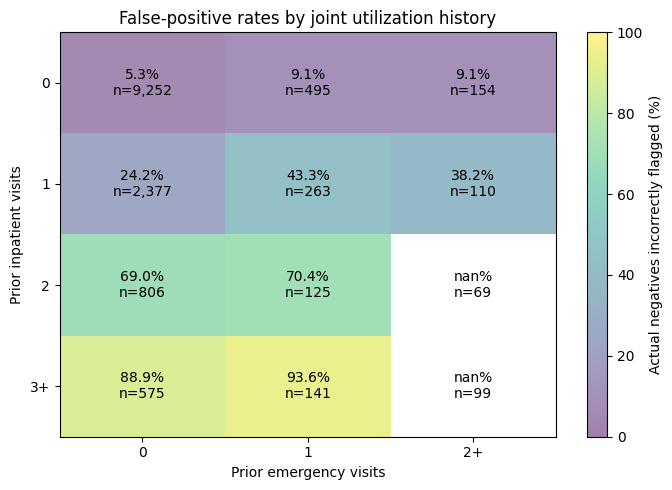

actual_negatives  false_positives    FPR
inpatient_band emergency_band                                          
0              0                           9252              486  0.053
               1                            495               45  0.091
               2+                           154               14  0.091
1              0                           2377              575  0.242
               1                            263              114  0.433
               2+                           110               42  0.382
2              0                            806              556  0.690
               1                            125               88  0.704
               2+                            69               58  0.841
3+             0                            575              511  0.889
               1                            141              132  0.936
               2+                            99               95  0.960

In [ ]:
audit["inpatient_band"] = pd.cut(pd.to_numeric(audit["number_inpatient"], errors="coerce"), bins=[-float("inf"), 0, 1, 2, float("inf")], labels=["0", "1", "2", "3+"])

audit["emergency_band"] = pd.cut(pd.to_numeric(audit["number_emergency"], errors="coerce"), bins=[-float("inf"), 0, 1, float("inf")], labels=["0", "1", "2+"])

negative = audit.loc[audit["target"].eq(0)]

joint = negative.groupby(["inpatient_band", "emergency_band"], observed=True)["y_pred"].agg(actual_negatives="size", false_positives="sum", FPR="mean")

counts = joint["actual_negatives"].unstack().reindex(index=["0", "1", "2", "3+"],columns=["0", "1", "2+"]).fillna(0)

rates = 100 * joint["FPR"].unstack().reindex_like(counts)
shown = rates.where(counts >= 100)

plt.figure(figsize=(7, 5))
plt.imshow(shown.to_numpy(dtype=float), aspect="auto",vmin=0, vmax=100, alpha=0.5)

plt.xticks(range(len(shown.columns)), shown.columns)
plt.yticks(range(len(shown.index)), shown.index)

for i in range(len(shown.index)):
    for j in range(len(shown.columns)):
        plt.text(j, i, f"{shown.iloc[i, j]:.1f}%\nn={int(counts.iloc[i, j]):,}", ha="center", va="center")

plt.xlabel("Prior emergency visits")
plt.ylabel("Prior inpatient visits")
plt.title("False-positive rates by joint utilization history")
plt.colorbar(label="Actual negatives incorrectly flagged (%)")
plt.tight_layout()
plt.show()

display(joint.round(3))

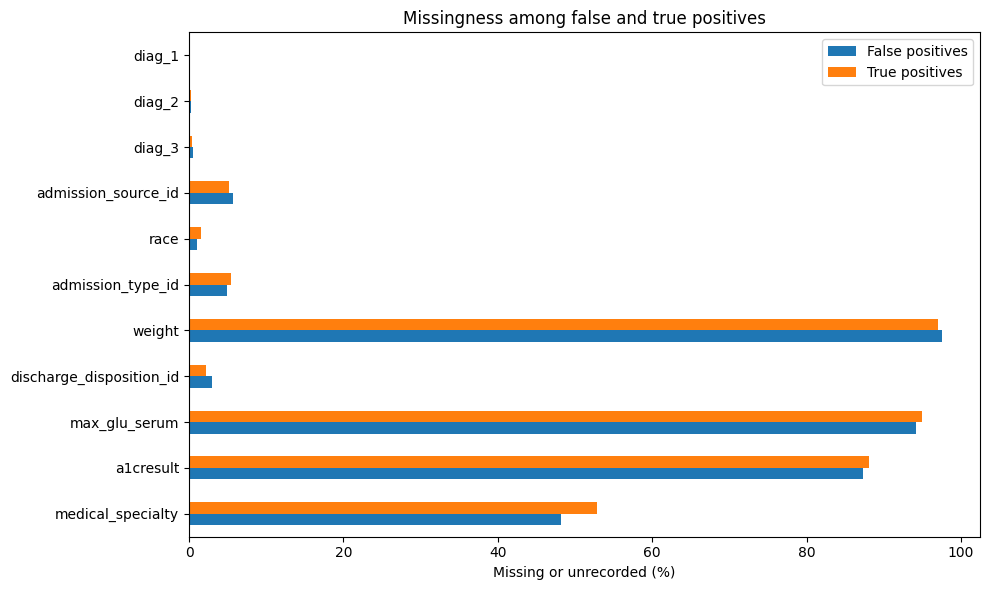

,False positives,True positives,difference_percentage_points
medical_specialty,48.16,52.78,-4.63
a1cresult,87.26,88.10,-0.84
max_glu_serum,94.15,94.94,-0.79
discharge_disposition_id,2.91,2.15,0.76
weight,97.57,96.96,0.61
admission_type_id,4.86,5.44,-0.58
race,1.07,1.52,-0.45
admission_source_id,5.63,5.19,0.44
diag_3,0.48,0.38,0.10
diag_2,0.18,0.25,-0.07


In [ ]:
columns = [column for column in flagged.columns if column not in ["target", "y_pred", "result", "patient_nbr", "encounter_id"]]

missing = flagged[columns].isna() | flagged[columns].astype("string").isin(["?", "", "missing"])

missing_rates = 100 * pd.DataFrame({"False positives": missing.loc[flagged["result"].eq("FP")].mean(),
                                    "True positives": missing.loc[flagged["result"].eq("TP")].mean()})

missing_rates = missing_rates.loc[missing_rates.gt(0).any(axis=1)]

difference = missing_rates["False positives"] - missing_rates["True positives"]

order = difference.abs().nlargest(12).index

if len(order):
    missing_rates.loc[order].plot.barh(figsize=(10, 6))
    plt.xlabel("Missing or unrecorded (%)")
    plt.ylabel("")
    plt.title("Missingness among false and true positives")
    plt.tight_layout()
    plt.show()

    display(missing_rates.assign(difference_percentage_points=difference).loc[order].round(2))